In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
df = pd.read_csv("./amz_uk_price_prediction_dataset.csv")

In [4]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


Part 1: Understanding Product Categories
Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

Frequency Tables:

- Generate a frequency table for the product category.
- Which are the top 5 most listed product categories?


In [10]:
frequency_table = df['category'].value_counts().sort_values(ascending=False)

In [25]:
frequency_table.head(5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

Visualizations:

Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?


<Axes: >

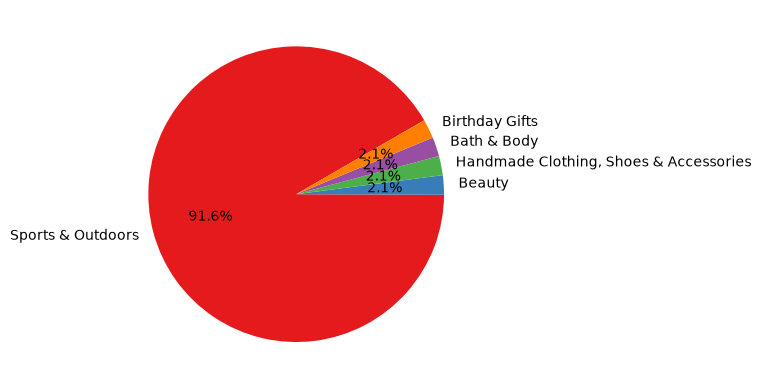

In [24]:
df['category'].value_counts().head(5).plot.pie(autopct='%1.1f%%', startangle=30, colors=sns.color_palette("Set1"))

It is very visible that sport & outdoors is the most frequent category, being used in almost 92% of the products

Part 2: Delving into Product Pricing
Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

Measures of Centrality:

- Calculate the mean, median, and mode for the price of products.
- What's the average price point of products listed? How does this compare with the most common price point (mode)?


In [26]:
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

mean_price, median_price, mode_price

(np.float64(89.24380943923661), np.float64(19.09), np.float64(9.99))

The mean price is nearly 9 times higher than the mode. The median sits much closer to the mode than to the mean.

Measures of Dispersion:

- Determine the variance, standard deviation, range, and interquartile range for product price.
- How varied are the product prices? Are there any indicators of a significant spread in prices?


In [29]:
df['price'].var()

np.float64(119445.48532254901)

In [30]:
df['price'].std()

np.float64(345.60886175349873)

In [33]:
df['price'].max() - df['price'].min() #range

np.float64(100000.0)

In [37]:
df['price'].quantile(0.75) - df['price'].quantile(0.25) # interquartile range 

np.float64(36.0)

There is an extremely high spread and variation. STD is nearly 4x of the mean.
The variance is huge, reflecting that deviations from the average price are very large when squared.  

Visualizations:

- Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
- Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

<Axes: xlabel='price', ylabel='Count'>

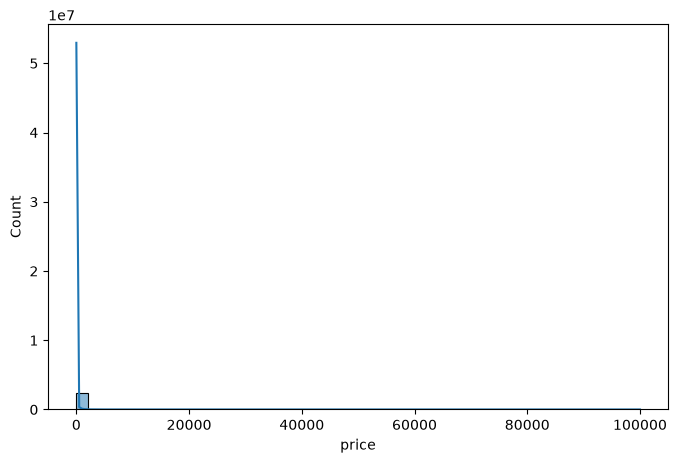

In [42]:
plt.figure(figsize=(8, 5))
sns.histplot(df["price"], bins=50, kde=True)

Because the data has extreme high-price outliers, a standard histogram shows one massive bar.
We can filter to focus on the specific bulk of data, e.g. under 100$:

<Axes: xlabel='price', ylabel='Count'>

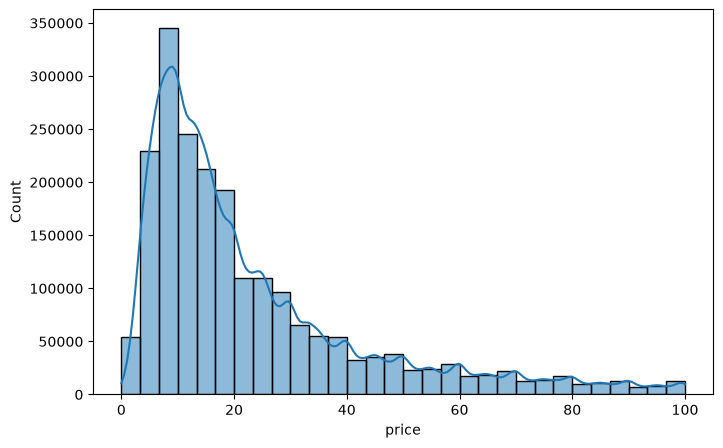

In [47]:
plt.figure(figsize=(8, 5))
sns.histplot(df[df["price"] <= 100]["price"], bins=30, kde=True) 
#shows that most products are around 10$

<Axes: ylabel='price'>

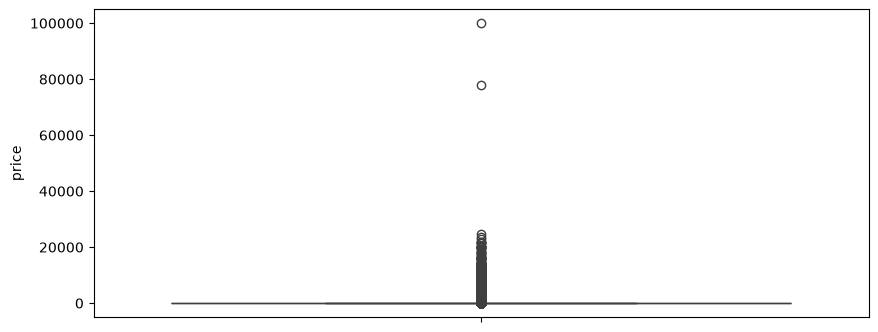

In [50]:
plt.figure(figsize=(10, 4))
sns.boxplot(data = df['price'])

Are there products that are priced significantly higher than the rest? Yes, there are significant extreme outliers. Any product priced above 99$ is plotted individually as outlier.   
Because prices extend far beyond hundreds and thousands of dollars, the box plot shows a dense cluster of outlier dots extending across the right-hand side.

Measures of Centrality:

- Calculate the mean, median, and mode for the rating of products.
- How do customers generally rate products? Is there a common trend?

In [54]:
mean_price = df['stars'].mean()
median_price = df['stars'].median()
mode_price = df['stars'].mode()[0]

mean_price, median_price, mode_price

(np.float64(2.152836472966066), np.float64(0.0), np.float64(0.0))

In [58]:
df['stars'].value_counts().head()

stars
0.0    1225641
4.5     151577
4.6     136995
4.4     136165
5.0     128492
Name: count, dtype: int64

Most of the customer do not leave a rating which affects the centrality measures negatively. 
Even though, 4.5. is the second most frequest rating, the amount of zeros leaves it out of the big picture.
However, when customers do rate products, they rate them overwhelmingly positively.

Measures of Dispersion:

- Determine the variance, standard deviation, and interquartile range for product rating.
- Are the ratings consistent, or is there a wide variation in customer feedback?

In [63]:
df['stars'].var()

np.float64(4.817434029796864)

In [64]:
df['stars'].std()

np.float64(2.194865378513421)

In [65]:
df['stars'].quantile(0.75) - df['stars'].quantile(0.25) # interquartile range 

np.float64(4.4)

The statistical indicators suggest extreme variation and inconsistency. 
On a 5-star rating scale the indicators are massive—spanning nearly the full range of possible values.
Over half the items in the store have zero reviews, however the system treats them as a very negative "0.0" value.

Shape of the Distribution:

- Calculate the skewness and kurtosis for the rating column.
- Are the ratings normally distributed, or do they lean towards higher or lower values?

In [69]:
df['stars'].skew()

np.float64(0.08120735761080881)

In [70]:
df['stars'].kurtosis()

np.float64(-1.9260061280432994)

The rating are not normally distributed. A normal distribution requires a kurtosis close to 0, while the calculations shows -1.93. 
On the other hand, skewness is near 0, which usually implies symmetry. 
Here, the distribution appears mathematically symmetric only because the two extremes cancel each other out. 
The dataset is split between unrated items (0.0) and high ratings (4.4–5.0).

Visualizations:

- Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

<Axes: xlabel='stars', ylabel='Count'>

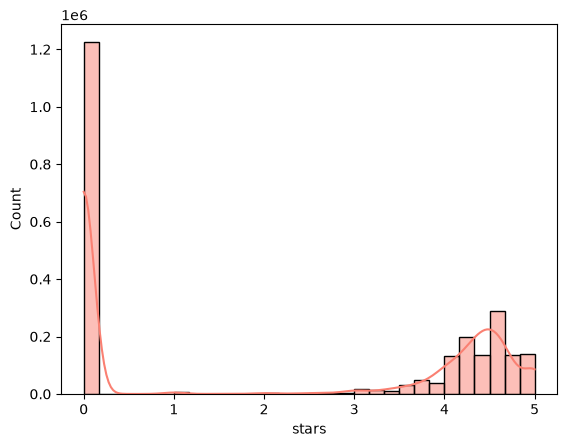

In [72]:
sns.histplot(df['stars'], kde=True, bins=30, color="salmon")

The histogram reveals that the vast majority of listings have a rating of 0.0 (over 1.2 million products), representing unrated items without reviews. However, there is a second clear cluster between 4.0 and 5.0 stars—peaking around 4.5 confirming our earlier inference that when customers do leave feedback, they rate products overwhelmingly positively. The kde line highlights this distribution, showing two distinct peaks at the extreme ends rather than a standard bell curve.